## PART 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Using: cpu


In [3]:
def preprocess(image):
    """ prepro 210x160x3 uint8 frame into 6400 (80x80) 2D float array """
    image = image[35:195] # crop
    image = image[::2,::2,0] # downsample by factor of 2
    image[image == 144] = 0 # erase background (background type 1)
    image[image == 109] = 0 # erase background (background type 2)
    image[image != 0] = 1 # everything else (paddles, ball) just set to 1
    return np.reshape(image.astype(np.float32).ravel(), [80,80])

class CartPolePolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.net(x)


class PongPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 8, stride=4), nn.ReLU(),
            nn.Conv2d(16, 32, 4, stride=2), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.net(x)


def discounted_returns(rewards, gamma):
    result = []
    running = 0.0
    for reward in reversed(rewards):
        running = reward + gamma * running
        result.append(running)
    return torch.tensor(result[::-1], dtype=torch.float32)


def run_episode(env, policy, game, training=True):
    observation, _ = env.reset()
    rewards, log_probs = [], []

    if game == "pong":
        frame = preprocess(observation)
        previous_frame = np.zeros_like(frame)

    done = False
    while not done:
        if game == "cartpole":
            state = torch.as_tensor(
                observation, dtype=torch.float32, device=device
            ).unsqueeze(0)
        else:
            state = torch.as_tensor(
                frame - previous_frame, dtype=torch.float32, device=device
            ).unsqueeze(0).unsqueeze(0)

        if training:
            logits = policy(state)
            distribution = Categorical(logits=logits)
            choice = distribution.sample()
            log_probs.append(distribution.log_prob(choice).squeeze())
        else:
            with torch.no_grad():
                logits = policy(state)
                choice = logits.argmax(dim=1)

        index = int(choice.item())
        action = index if game == "cartpole" else (2, 3)[index]
        next_observation, reward, terminated, truncated, _ = env.step(action)
        rewards.append(float(reward))
        done = terminated or truncated

        if game == "pong":
            previous_frame = frame
            frame = preprocess(next_observation)
        observation = next_observation

    return rewards, log_probs


In [ ]:
def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)
    result = np.full(len(values), np.nan)
    if len(values) >= window:
        result[window - 1:] = np.convolve(values, np.ones(window) / window, mode="valid")
    return result

def train(game, episodes, gamma, learning_rate=0.01, seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    env_id = "CartPole-v1" if game == "cartpole" else "ALE/Pong-v5"
    env = gym.make(env_id)
    policy = (CartPolePolicy() if game == "cartpole" else PongPolicy()).to(device)
    optimizer = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    episode_rewards = []

    try:
        for episode in range(episodes):
            policy.train()
            rewards, log_probs = run_episode(env, policy, game, training=True)
            returns = discounted_returns(rewards, gamma).to(device)
            loss = -(torch.stack(log_probs) * returns).sum()

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=10.0)
            optimizer.step()

            episode_rewards.append(sum(rewards))
            if (episode + 1) % 100 == 0:
                print(
                    f"{game}: {episode + 1}/{episodes}, "
                    f"last 100 mean = {np.mean(episode_rewards[-100:]):.2f}"
                )
    finally:
        env.close()

    return policy, np.asarray(episode_rewards)


def plot_training(rewards, game):
    plt.plot(rewards, alpha=0.35, label="Episode reward")
    plt.plot(moving_average(rewards), linewidth=2,label="100-episode moving average")
    plt.xlabel("Training episode")
    plt.ylabel("Total episode reward")
    plt.title(f"{game.title()} training")
    plt.legend()
    plt.show()


def evaluate(policy, game, n_episodes=500):
    env_id = "CartPole-v1" if game == "cartpole" else "ALE/Pong-v5"
    env = gym.make(env_id)
    policy.eval()
    totals = []
    try:
        for episode in range(n_episodes):
            rewards, _ = run_episode(env, policy, game, training=False)
            totals.append(sum(rewards))
            if (episode + 1) % 100 == 0:
                print(f"Evaluated {episode + 1}/{n_episodes}")
    finally:
        env.close()

    totals = np.asarray(totals)
    print(f"Mean: {totals.mean():.3f}")
    print(f"Standard deviation: {totals.std():.3f}")
    plt.figure(figsize=(8, 4))
    plt.hist(totals, bins=25, edgecolor="black")
    plt.xlabel("Total episode reward")
    plt.ylabel("Number of episodes")
    plt.title(f"{game.title()}: {n_episodes} evaluation episodes")
    plt.tight_layout()
    plt.savefig(f"{game}_evaluation_histogram.png", dpi=160)
    plt.show()
    return totals

### Cartpole Game

cartpole: 100/500, last 100 mean = 24.05
cartpole: 200/500, last 100 mean = 20.06
cartpole: 300/500, last 100 mean = 27.16
cartpole: 400/500, last 100 mean = 53.78
cartpole: 500/500, last 100 mean = 63.20


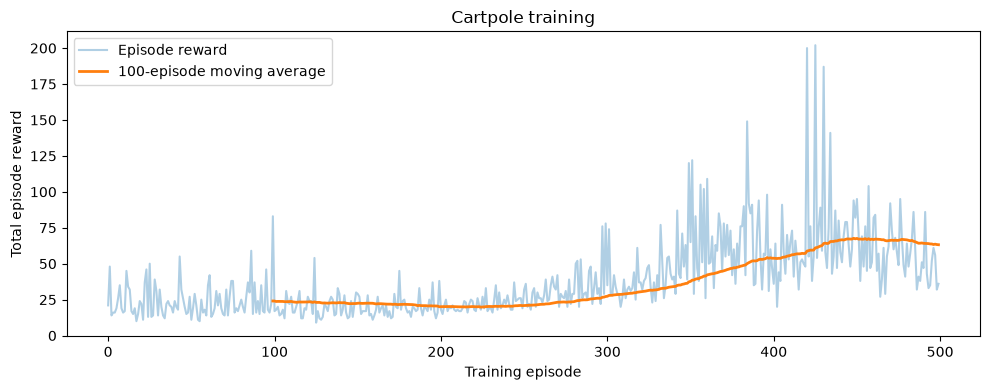

In [20]:
cartpole_policy, cartpole_rewards = train(game="cartpole", episodes=500, gamma=0.95, learning_rate=0.0007)
plot_training(cartpole_rewards, "cartpole")

Evaluated 100/500
Evaluated 200/500
Evaluated 300/500
Evaluated 400/500
Evaluated 500/500
Mean: 52.164
Standard deviation: 8.751


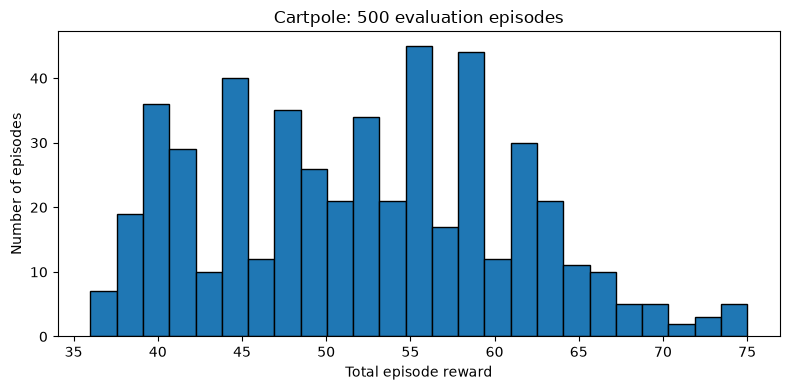

In [21]:
cartpole_eval_rewards = evaluate(cartpole_policy, "cartpole", n_episodes=500)

Edge cases and tests

In [ ]:
r = [1., 1., 1.]
## Test that discounted_returns with gamma=0 returns the same rewards
assert torch.allclose(discounted_returns(r, 0), torch.tensor(r))
## Test that discounting increases the return of the first timestep
assert discounted_returns(r, 0.95)[0] > discounted_returns(r, 0)[0]

## Random Policy Baseline for CartPole
def random_cartpole_mean(seeds):
    env = gym.make("CartPole-v1")
    scores = []

    try:
        for seed in seeds:
            _, _ = env.reset(seed=seed)
            env.action_space.seed(seed)
            done, total = False, 0

            while not done:
                _, reward, terminated, truncated, _ = env.step(
                    env.action_space.sample()
                )
                total += reward
                done = terminated or truncated

            scores.append(total)
    finally:
        env.close()

    return np.mean(scores)

random_mean = random_cartpole_mean(range(100))
## Test that the trained policy outperforms a random policy
assert np.mean(cartpole_eval_rewards) > random_mean, (
    f"Trained mean {np.mean(cartpole_eval_rewards):.1f} "
    f"did not exceed random mean {random_mean:.1f}"
)

### Pong Game

pong: 100/500, last 100 mean = -20.50
pong: 200/500, last 100 mean = -20.45
pong: 300/500, last 100 mean = -20.48
pong: 400/500, last 100 mean = -20.51
pong: 500/500, last 100 mean = -20.46


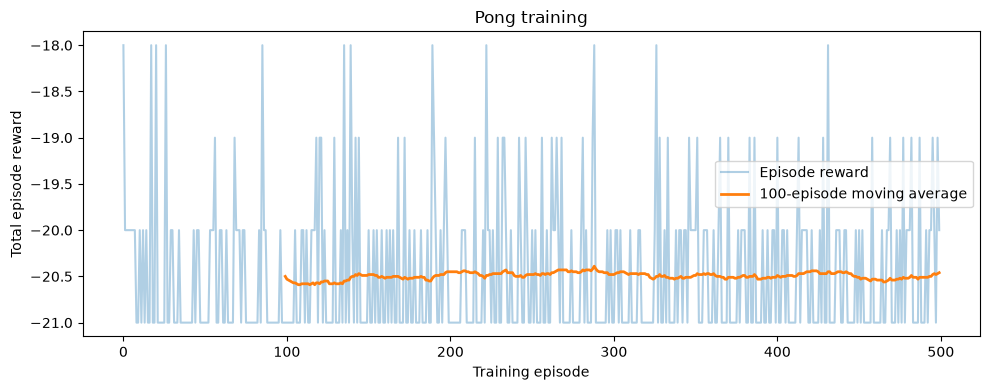

In [ ]:
pong_policy, pong_rewards = train(
    game="pong", episodes=500, gamma=0.99, learning_rate=0.0001
)
plot_training(pong_rewards, "pong")

Evaluated 100/500
Evaluated 200/500
Evaluated 300/500
Evaluated 400/500
Evaluated 500/500
Mean: -21.000
Standard deviation: 0.000


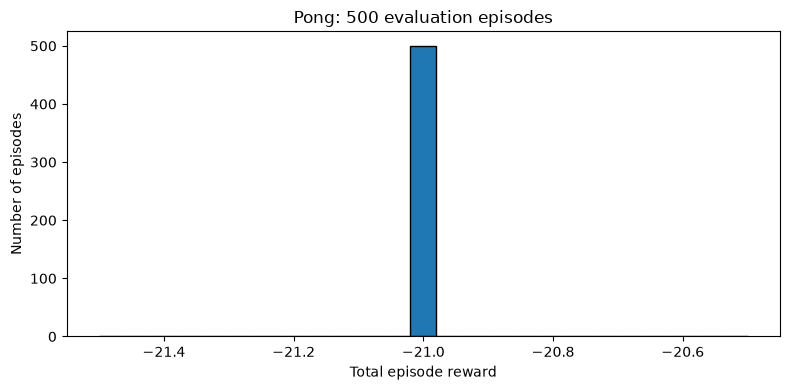

In [38]:
pong_eval_rewards = evaluate(pong_policy, "pong", n_episodes=500)

Edge cases and Tests for Pong game

In [39]:
r = [0., 0., 1.]
## Test that discounted_returns with gamma=0 returns the same rewards
assert np.isclose(discounted_returns(r, 0.99)[0].item(), 0.99**2)
## Test that discounting increases the return of the first timestep
assert discounted_returns(r, 0)[0].item() == 0

## Test that the trained policy outperforms a random policy
assert np.mean(pong_eval_rewards) > -20, (
    f"Pong evaluation mean is {np.mean(pong_eval_rewards):.2f}; "
    "the policy has not escaped near-total losses"
)

AssertionError: Pong evaluation mean is -21.00; the policy has not escaped near-total losses

## PART 2

In [11]:
def train(game, episodes, gamma, learning_rate=0.01, seed=42, baseline_decay=None):
    np.random.seed(seed)
    torch.manual_seed(seed)

    env_id = "CartPole-v1" if game == "cartpole" else "ALE/Pong-v5"
    env = gym.make(env_id)
    env.reset(seed=seed)
    policy = (CartPolePolicy() if game == "cartpole" else PongPolicy()).to(device)
    optimizer = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    episode_rewards = []
    baseline = 0.0  # Scalar, held fixed throughout each episode

    try:
        for episode in range(episodes):
            policy.train()
            rewards, log_probs = run_episode(env, policy, game, training=True)
            returns = discounted_returns(rewards, gamma).to(device)
            weights = returns if baseline_decay is None else returns - baseline
            loss = -(torch.stack(log_probs) * weights).sum()

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=10.0)
            optimizer.step()

            if baseline_decay is not None:
                baseline = baseline_decay * baseline + (1.0 - baseline_decay) * returns.mean().item()

            episode_rewards.append(sum(rewards))
            if (episode + 1) % 100 == 0:
                print(
                    f"{game}: {episode + 1}/{episodes}, "
                    f"last 100 mean = {np.mean(episode_rewards[-100:]):.2f}"
                )
    finally:
        env.close()

    return policy, np.asarray(episode_rewards)

### Cartpole

cartpole: 100/500, last 100 mean = 64.81
cartpole: 200/500, last 100 mean = 183.20
cartpole: 300/500, last 100 mean = 227.38
cartpole: 400/500, last 100 mean = 302.22
cartpole: 500/500, last 100 mean = 340.01


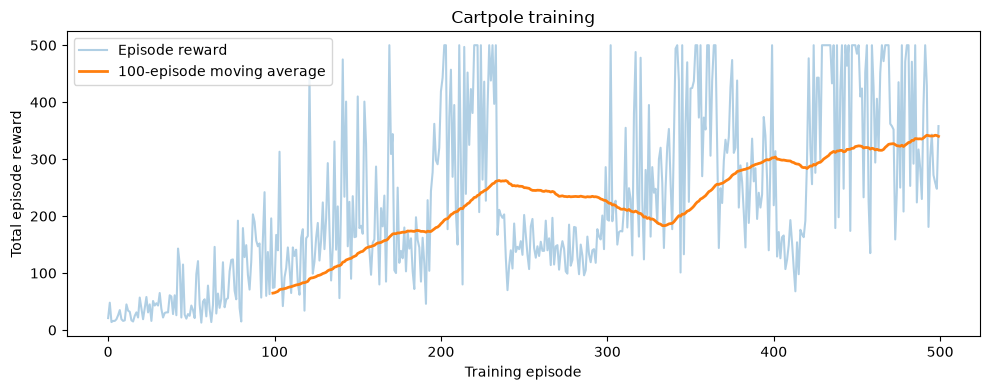

Evaluated 100/500
Evaluated 200/500
Evaluated 300/500
Evaluated 400/500
Evaluated 500/500
Mean: 486.362
Standard deviation: 40.372


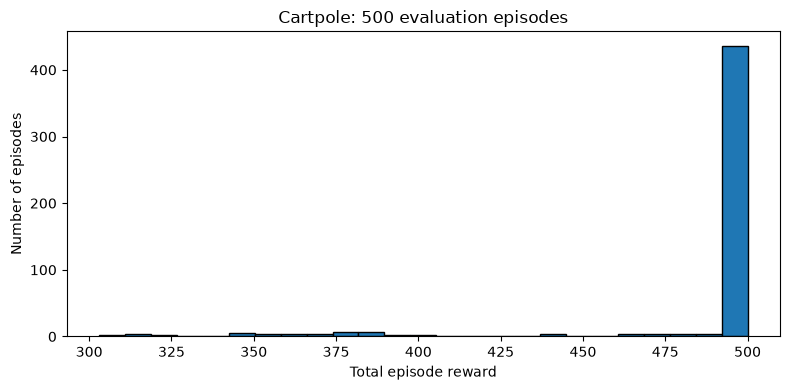

In [40]:
cartpole_baseline_policy, cartpole_baseline_rewards = train(
    game="cartpole",
    episodes=500,
    gamma=0.95,
    learning_rate=0.0007,
    seed=42,
    baseline_decay=0.9,
)
plot_training(cartpole_baseline_rewards, "cartpole")
cartpole_baseline_eval = evaluate(cartpole_baseline_policy, "cartpole", n_episodes=500)


Edge cases and Tests

In [ ]:
p = 0.8
action_probabilities = np.array([1 - p, p])
log_probability_gradients = np.array([-p, 1 - p])
rewards = np.array([0., 1.])
baseline = 0.2

gradient_without = np.sum(
    action_probabilities * log_probability_gradients * rewards
)
gradient_with = np.sum(
    action_probabilities * log_probability_gradients
    * (rewards - baseline)
)

## Test that baseline preserves the expected policy gradient
assert np.isclose(gradient_without, gradient_with)

## Test that the baseline CartPole policy performs at least 80% as well as the original policy
assert np.mean(cartpole_baseline_eval) >= 0.8 * np.mean(cartpole_eval_rewards), (
    "Baseline CartPole performs substantially worse than Part 1"
)

### Pong

pong: 100/500, last 100 mean = -20.44
pong: 200/500, last 100 mean = -20.32
pong: 300/500, last 100 mean = -20.27
pong: 400/500, last 100 mean = -20.34
pong: 500/500, last 100 mean = -20.32


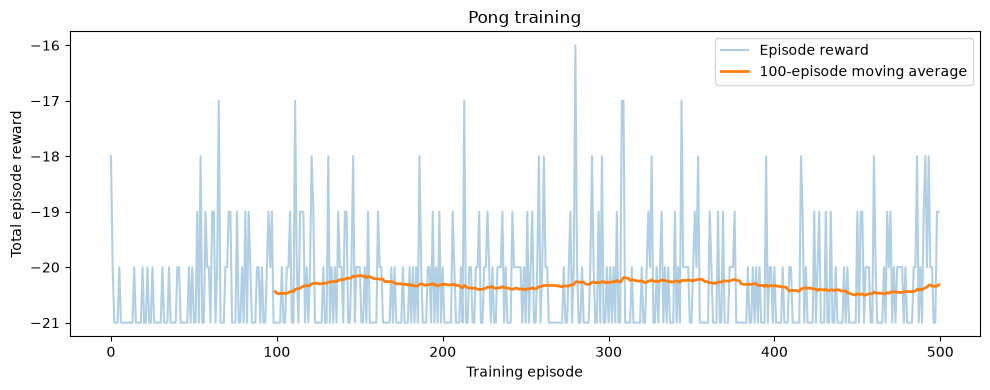

Evaluated 100/500
Evaluated 200/500
Evaluated 300/500
Evaluated 400/500
Evaluated 500/500
Mean: -21.000
Standard deviation: 0.000


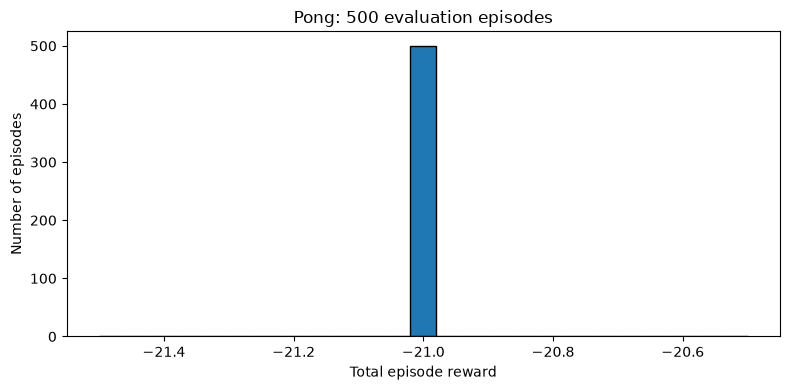

In [25]:
pong_baseline_policy, pong_baseline_rewards = train(
    game="pong",
    episodes=500,
    gamma=0.99,
    learning_rate=0.0001,
    seed=42,
    baseline_decay=0.9,
)
plot_training(pong_baseline_rewards, "pong")
pong_baseline_eval = evaluate(pong_baseline_policy, "pong", n_episodes=500)


Edge cases and tests

In [42]:
def test_pong_baseline_gradient_variance(policy, gamma=0.99, n=12):
    env = gym.make("ALE/Pong-v5")
    output_bias = list(policy.parameters())[-1]
    baseline = 0.0
    gradients_without, gradients_with = [], []

    try:
        for _ in range(n):
            rewards, log_probs = run_episode(env, policy, "pong", training=True)
            G = discounted_returns(rewards, gamma).to(device)
            log_probs = torch.stack(log_probs)

            loss_without = -(log_probs * G).sum()
            loss_with = -(log_probs * (G - baseline)).sum()

            g0 = torch.autograd.grad(
                loss_without, output_bias, retain_graph=True
            )[0]
            gb = torch.autograd.grad(loss_with, output_bias)[0]

            gradients_without.append(g0.detach().cpu().numpy().copy())
            gradients_with.append(gb.detach().cpu().numpy().copy())

            baseline = 0.9 * baseline + 0.1 * G.mean().item()
    finally:
        env.close()

    var0 = np.stack(gradients_without).var(axis=0).sum()
    varb = np.stack(gradients_with).var(axis=0).sum()
    print("Without baseline:", var0, "With baseline:", varb)

    assert varb < var0, "current baseline implementation does not reduce gradient variance"


test_pong_baseline_gradient_variance(pong_baseline_policy)

Without baseline: 1936.0674 With baseline: 1211.2275


In [ ]:
scores = np.asarray(pong_baseline_eval)
print("Mean:", scores.mean())
print("Standard deviation:", scores.std())
print("Fraction at -21:", np.mean(scores == -21))

assert not (scores.std() == 0 and scores.mean() == -21), (
    "Part 2 Pong baseline: evaluation scores are all -21, policy has collapsed to always lose"
)

Mean: -21.0
Standard deviation: 0.0
Fraction at -21: 1.0


AssertionError: Part 2 Pong 稳定地每局输到 -21；零方差不是训练成功